In [1]:
import math
import numpy as np
import tensorflow as tf

from plotly.subplots import make_subplots
import plotly.graph_objects as go

from tf_ofcs.components import *
from tf_ofcs.reference_systems import PAMSystem
from tf_ofcs.datatypes import Signal, Timing, TensorCompatible
from tf_ofcs.utils import dbm_to_w, from_db, to_tensor, pam_constellation, symbol_mapping_to_gray
from tf_ofcs.plot import *

from typing import Optional

2025-03-12 16:59:27.731408: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-12 16:59:27.769673: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-03-12 16:59:27.769699: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-12 16:59:27.771088: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-12 16:59:27.777497: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-12 16:59:27.778215: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [6]:
Component.trace_debug_enabled_by_default = False

system = PAMSystem(n_taps=13, bits_per_symbol=2)
ber_tester = BERTester(system, rng=system.rng)

system.set_channel(Composition([
    PadSignal(0.125),
    OpticalFiber(
        attenuation=[0.22],
        length=[40.0],
        chromatic_dispersion=[17.0],
        eff_non_linear_coeff=[1.76],
        central_frequency=193.414e12,
        step_count=1,
        enable_nonlinear_effects=False,
        name="fiber"
    ),
    PadSignal(0.125, unpad=True),
    OpticalAWGN(relative_db=[-30.0], rng=system.rng, name="channel_noise"),
], name="channel"))

system_params = {
    "bit_sequence_generator__length": tf.constant(32),
    "lpf__symbol_rate": tf.constant(32e9)
}

In [7]:
def plot(chromatic_dispersion, fiber_length, attenuation, osnr, rolloff_factor):
    params = system_params
    params["fiber__chromatic_dispersion"] = to_tensor([chromatic_dispersion])
    params["fiber__length"] = to_tensor([fiber_length])
    params["fiber__attenuation"] = to_tensor([attenuation])
    params["channel_noise__relative_db"] = to_tensor([-osnr])
    params["lpf__rolloff_factor"] = to_tensor(rolloff_factor)

    system.rng.reset_from_seed(1)

    params["bit_sequence_generator__length"] = tf.constant(256)

    system.setup(system.channel.substitute, params)

    params["bit_sequence_generator__length"] = tf.constant(32)
    system.trace(system.bitseq_generator.trace(**params), **params)

    input_signal = system.find_child("bit_sequence_generator").output

    fig = make_subplots(
        rows=3,
        cols=1,
        subplot_titles=(
            "Bit sequence",
            "Encoded signal",
            "Optical signal"
        ),
        vertical_spacing = 0.05
    )

    plot_bitseq(input_signal, fig, 0, row=1, col=1, label="Input sequence")
    plot_bitseq(system.output, fig, row=1, col=1, label="Output sequence")

    offset_signal = TruncateSignal(left=0.5 / (system.data_rate / float(system.bits_per_symbol)), mode="time")

    encoded = system.find_child("pam_symbol_encoder").output
    encoded = offset_signal(encoded)
    before_filter = system.find_child("before_filter").output
    before_filter = offset_signal(Gain(tf.math.reduce_sum(system.rx_filter.taps))(before_filter))
    
    plot_envelope(encoded, fig, row=2, col=1, label="Encoded signal")
    plot_envelope(system.find_child("receiver").output, fig, row=2, col=1, label="Received signal")
    plot_envelope(before_filter, fig, row=2, col=1, label="Received signal (before filter)")
    
    plot_power(system.find_child("transmitter").output, fig, row=3, col=1, label="Transmitted signal")
    plot_power(system.find_child("channel").output, fig, row=3, col=1, label="Signal after fiber")

    fig.update_layout(
        autosize=True,
        height=1000
    )

    return fig


import ipywidgets

ipywidgets.interact(
    plot,
    chromatic_dispersion=(-100.0, 100.0, 1.0),
    fiber_length=(0.0, 65.0, 1.0),
    attenuation=(0.0, 0.4, 0.01),
    osnr=(-10.0, 80.0, 1.0),
    rolloff_factor=(0.0, 1.0, 0.01)
)

interactive(children=(FloatSlider(value=0.0, description='chromatic_dispersion', min=-100.0, step=1.0), FloatS…

<function __main__.plot(chromatic_dispersion, fiber_length, attenuation, osnr, rolloff_factor)>

In [19]:
%time ber_tester(tf.constant(256), **system_params, ber_tester__n_iterations=tf.constant(10), ber_tester__batch_size=tf.constant(5000))

CPU times: user 12.8 s, sys: 1.5 s, total: 14.3 s
Wall time: 5.81 s


<tf.Tensor: shape=(), dtype=float32, numpy=0.0>

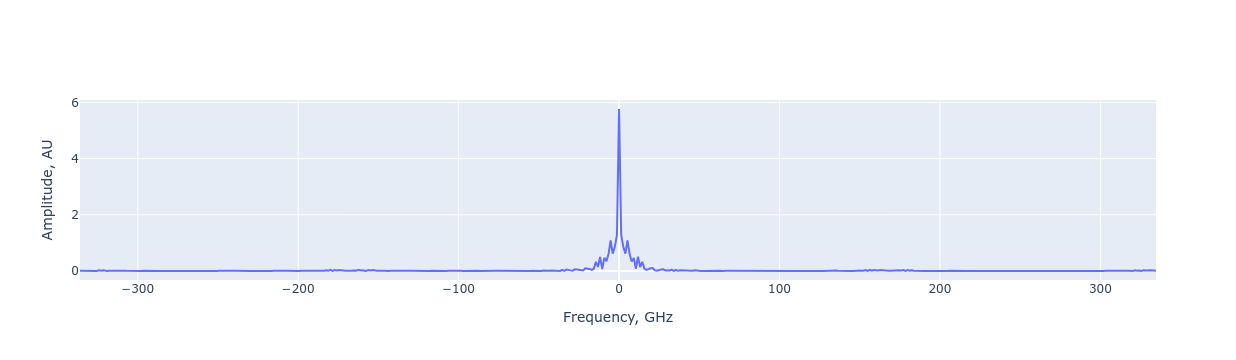

In [4]:
plot_spectrum(system.find_child("channel").output)